# Exercise recognition smoke test
Model: `prithivMLmods/Gym-Workout-Classifier-SigLIP2`.

Classify **squat, push-up, lateral raise**, keeping all other labels available for rejection.

Data: [averrous/workout test split](https://huggingface.co/datasets/averrous/workout) and [UCF101 workout subset](https://huggingface.co/datasets/ambarishnarayan/UFC101_Subset_Workout).

This is a small smoke test, not evidence of phone or simulator performance. Training overlap with the image dataset is unknown. Thresholds are fixed heuristics, not calibrated confidence.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if ROOT.name != 'exercise_demo':
    ROOT = ROOT / 'exercise_demo'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Project:', ROOT)

Project: /Users/soniakoszut/Documents/ChatGPT/Physical AI Hackathon/exercise_demo


## Re-run inference
Dependencies live in the project `.venv`. Download assets once with `python exercise_demo/download_data.py` from the workspace root. Uncomment the next lines to rerun every prediction; the saved tables below are from the completed run.

In [2]:
# from evaluate import evaluate
# predictions, summary = evaluate(per_class=20)

In [3]:
import pandas as pd
summary = json.loads(Path('results/summary.json').read_text())
print(json.dumps(summary, indent=2))
pd.read_csv('results/image_confusion.csv', index_col=0)

{
  "model": "/Users/soniakoszut/Documents/ChatGPT/Physical AI Hackathon/.cache/model",
  "device": "cpu",
  "dataset": "averrous/workout",
  "split": "test",
  "seed": 42,
  "threshold": 0.65,
  "margin": 0.15,
  "samples": 100,
  "raw_top1_accuracy": 0.97,
  "target_or_unknown_accuracy": 0.96,
  "median_inference_ms": 53.074124502018094,
  "per_class": {
    "lateral raises": {
      "n": 20,
      "raw_correct": 19,
      "accepted_correct": 17
    },
    "plank": {
      "n": 20,
      "raw_correct": 20,
      "accepted_correct": 20
    },
    "push up": {
      "n": 20,
      "raw_correct": 20,
      "accepted_correct": 20
    },
    "shoulder press": {
      "n": 20,
      "raw_correct": 18,
      "accepted_correct": 20
    },
    "squat": {
      "n": 20,
      "raw_correct": 20,
      "accepted_correct": 19
    }
  },
  "limitations": [
    "Small sampled smoke test, not a benchmark.",
    "Model training data not disclosed; overlap with this image dataset cannot be excluded.",

,lateral_raise,pushup,squat,unknown
expected,,,,
lateral_raise,17,0,0,3
pushup,0,20,0,0
squat,0,0,19,1
unknown,0,0,0,40


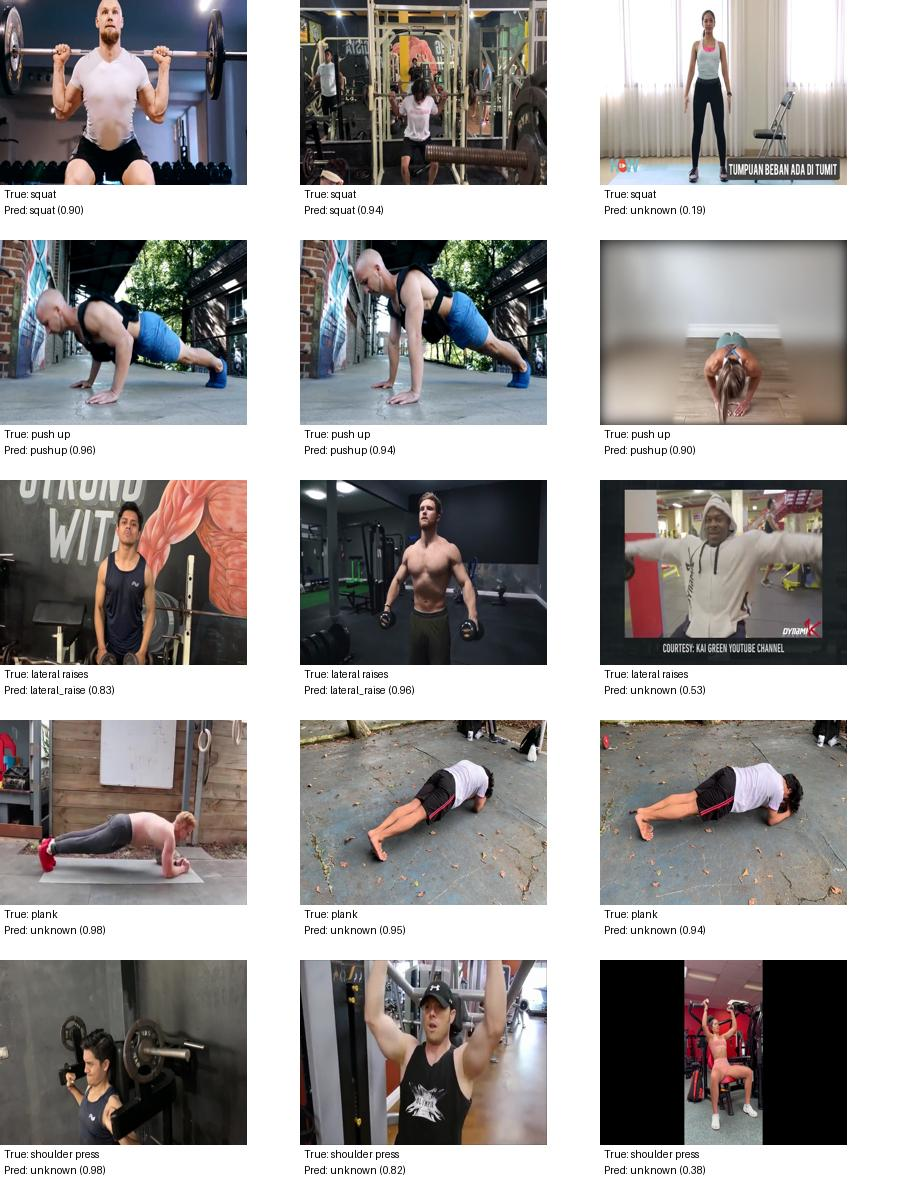

,source,sample,truth,expected,exercise,raw_label,score,inference_ms
2,workout_test,1138,squat,squat,unknown,squat,0.185229,87.712500
42,workout_test,589,lateral raises,lateral_raise,unknown,lateral raises,0.532647,67.352125
48,workout_test,590,lateral raises,lateral_raise,unknown,lateral raises,0.474035,128.771417
55,workout_test,629,lateral raises,lateral_raise,unknown,barbell biceps curl,0.289558,48.451333


In [4]:
from IPython.display import display, Image
display(Image(filename='results/examples.jpg'))
predictions = pd.read_csv('results/image_predictions.csv')
predictions[predictions.expected != predictions.exercise]

## Phone camera app
From the workspace root, follow `PHONE_SETUP.md` in this folder. The browser captures RGB frames and posts them to `/predict`; the same `ExerciseClassifier.predict()` handles dataset images and phone frames. Visible prediction output is only the exercise name. No technique review or robot control is included.

For simulation later, call `model.predict(rgb_array)` on the rendered camera image, or POST a JPEG render to `/predict`. Skeleton coordinates alone are not an input to this image model. Synthetic appearance is a separate domain requiring evaluation.